# 第 3 课｜用 PyTorch 跑通训练循环

你已在吴恩达课程中学过损失、梯度下降、前向传播和反向传播。这节直接把这些概念对应到 **PyTorch API**，不再手写求导或参数更新公式。

**核心问题：一个 batch 进入模型后，哪些语句依次让模型学到东西？**

- 本课需要你掌握：读懂训练循环；分清 `backward()` 和 `step()`；修改学习率并比较结果。
- 我搭好的部分：绘图工具、文件路径和运行验证，不要求你学习这些实现。
- 使用 CPU 和 64 个数值样本即可；本课不需要 GPU。这里拟合的是合成直线，不是论文数据，也还不是 VAE。

从上到下逐格运行。先完成默认实验，再改一个参数。

## 1．确认环境，准备 PyTorch

Notebook 使用已有的 `Python 3 (ipykernel)` 名称，实际环境以输出为准：应为 `D:\Anaconda3\envs\HEUhuqiao\python.exe`。如果路径不同，先在 PyCharm 选择现有 HEUhuqiao 环境。

`nn` 提供模型层与损失函数；`TensorDataset` 将输入和目标配对；`DataLoader` 负责分批取数据。

In [1]:
import sys
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

print("实际 Python：", sys.executable)
print("PyTorch：", torch.__version__)

实际 Python： D:\Anaconda3\envs\HEUhuqiao\python.exe
PyTorch： 2.11.0+cu128


## 2．先看数据：一个时刻对应一个频率

目标曲线是 `频率 = 8 + 4 × 时间`，单位分别是 kHz、秒。这里用已知公式制造练习数据；训练时优化器只通过预测误差调整模型参数。

时间共有 64 个采样点。`unsqueeze(1)` 把 `(64,)` 变成 `(64, 1)`：**64 个样本，每个样本只有 1 个输入特征**。目标也用 `(64, 1)`，与模型输出保持一致，避免广播导致错误的损失计算。

注意：这节一个“样本”是一个时间点，不是上一课的一整张图；batch 的含义取决于我们怎样定义样本。

In [4]:
time_s = torch.linspace(0.0, 1.0, 64).unsqueeze(1)  # 输入 X：(64, 1)
frequency_khz = 8.0 + 4.0 * time_s                 # 目标 y：(64, 1)
dataset = TensorDataset(time_s, frequency_khz)   # 第 i 项是 (X[i], y[i])

print("输入、目标形状：", time_s.shape, frequency_khz.shape)
print("第一个样本：", dataset[0])
print("最后一个样本：", dataset[-1])

输入、目标形状： torch.Size([64, 1]) torch.Size([64, 1])
第一个样本： (tensor([0.]), tensor([8.]))
最后一个样本： (tensor([1.]), tensor([12.]))


## 3．配置模型、损失函数、优化器和 batch

| 代码 | 你学过的概念 | 本例的含义 |
|---|---|---|
| `nn.Linear(1, 1)` | 模型 / 线性层 | 1 个输入特征 → 1 个输出，计算 `w × 时间 + b`；w、b 都要学习 |
| `nn.MSELoss()` | 损失函数 | 预测与目标的平方误差取平均；本例单位是 kHz² |
| `torch.optim.SGD(...)` | 梯度下降优化器 | 接收要更新的参数及学习率；创建它本身不会训练 |
| `model.parameters()` | 可学习参数 | 把模型的 w、b 交给优化器，不需要自己逐个更新 |
| `DataLoader(...)` | 取 mini-batch | 每批 16 个样本，遍历一次有 4 批；`shuffle=True` 每轮打乱次序 |

`torch.manual_seed(42)` 固定本例初始化的随机种子；DataLoader 的独立随机数生成器固定洗牌起点，便于在同一环境中比较实验。`num_workers=0` 在当前进程取数据，适合这个小例子。

**实验重置入口：**修改学习率后，从下面这一格重新往下运行，它会重新创建模型、优化器和 DataLoader。只重跑训练循环会继续训练旧模型，无法公平比较。

In [10]:
# ===== 实验参数：第二次实验只把 learning_rate 改为 0.01 =====
learning_rate = 0.01
epochs = 120
batch_size = 16

# ===== 每次对比实验都重新初始化 =====
torch.manual_seed(42)
loader = DataLoader(
    dataset, batch_size=batch_size, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42),
)
model = nn.Linear(1, 1)                                # 模型：w*x+b
loss_fn = nn.MSELoss()                                # 损失函数：MSE
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)  # 优化器：SGD

print("每轮 batch 数：", len(loader))
print("初始 w、b：", model.weight.item(), model.bias.item())

每轮 batch 数： 4
初始 w、b： 0.7645385265350342 0.8300079107284546


## 4．训练前，记录模型的起点

`model(time_s)` 就是一次**前向传播**。`torch.no_grad()` 是上下文管理器：在缩进范围内，不建立用于反向传播的梯度记录，适合这里只观察、不训练的情况。

`.item()` 把只有一个元素的张量取成 Python 数值，方便打印和记录。这里记录的是整份训练数据上的初始 MSE。

In [11]:
with torch.no_grad():
    initial_prediction = model(time_s)  # 前向传播：此时尚未训练
    initial_mse = loss_fn(initial_prediction, frequency_khz).item()

print(f"训练前 MSE：{initial_mse:.6f}")

训练前 MSE：78.124115


## 5．训练循环：把理论对应到这五行

先读内层循环，再读外层循环。`for x_batch, y_batch in loader` 会取出一批配对数据，并把这对数据分别赋给两个变量。它们的形状都是 `(B, 1)`，本例 B=16。

```text
取一批数据 → 清空旧梯度 → 前向传播 → 计算损失 → 反向传播 → 更新参数
                   zero_grad     model(...)     loss_fn      backward       step
```

- **epoch**：完整遍历训练数据一次；本例每个 epoch 有 4 次参数更新。
- `model.train()`：切到训练模式，不会替你运行训练循环。当前只有 Linear，训练/评估模式不会改变它的计算；后面有 Dropout 等层时这个区别才体现出来。
- `zero_grad()`：清掉上一批留下的梯度。PyTorch 默认累加梯度，不会因为调用 `backward()` 就自动清零。
- **`loss.backward()` 计算梯度，`optimizer.step()` 才根据梯度更新参数。**SGD 的更新细节已经封装在优化器里。

`history` 用来记每轮平均损失。每批的 MSE 乘该批样本数，再除总样本数，是按样本加权的平均，即使最后一批不足 16 个也适用。它来自这一轮中不断变化的模型，不等于轮末固定模型重新算出的 MSE。

In [12]:
history = []
model.train()  # 切换模式；真正的训练发生在下面的循环中

for epoch in range(epochs):
    total_squared_error = 0.0

    for x_batch, y_batch in loader:  # 数据取批次：(B, 1)、(B, 1)
        optimizer.zero_grad()              # ① 梯度清零：清掉上一批的梯度
        prediction = model(x_batch)        # ② 前向传播：用当前参数得到预测
        loss = loss_fn(prediction, y_batch)  # ③ 计算损失：预测与目标的 MSE
        loss.backward()                    # ④ 反向传播：计算参数的梯度
        optimizer.step()                   # ⑤ 梯度下降：SGD 根据梯度更新 w、b

        # 这里只记录数值，不参与参数更新。size(0) 是本批样本数。
        total_squared_error += loss.item() * x_batch.size(0)

    epoch_mse = total_squared_error / len(dataset)
    history.append(epoch_mse)
    if epoch == 0 or (epoch + 1) % 20 == 0:
        print(f"epoch {epoch + 1:3d} / {epochs}，该轮平均损失 = {epoch_mse:.8f}")

epoch   1 / 120，该轮平均损失 = 72.45151901
epoch  20 / 120，该轮平均损失 = 1.47438216
epoch  40 / 120，该轮平均损失 = 0.03669468
epoch  60 / 120，该轮平均损失 = 0.01063561
epoch  80 / 120，该轮平均损失 = 0.00826394
epoch 100 / 120，该轮平均损失 = 0.00663512
epoch 120 / 120，该轮平均损失 = 0.00534360


## 6．训练结束：固定参数，观察预测

`model.eval()` 切到评估模式；**它不会自动关闭梯度记录**，所以预测时另用 `torch.no_grad()`。这两个操作的职责不同。

我们重新在全部训练点上计算 MSE，并查看拟合到的 w、b。`query_time` 是另选的输入时刻，用于演示模型调用。

**本节没有正式划分训练 / 验证 / 测试集，下面的训练 MSE 不能当作泛化性能或论文测试成绩。**下一课再加入数据划分和保存、加载模型。

In [13]:
model.eval()
with torch.no_grad():
    final_prediction = model(time_s)  # 固定已学参数后的前向传播
    final_mse = loss_fn(final_prediction, frequency_khz).item()
    query_time = torch.tensor([[0.25], [0.75]])  # 2 个样本、每个 1 个特征
    query_prediction = model(query_time)

print(f"训练前 MSE：{initial_mse:.8f} → 训练后 MSE：{final_mse:.8f}")
print(f"学到的 w = {model.weight.item():.6f}，b = {model.bias.item():.6f}")
print("输入时刻（秒）：", query_time.squeeze(1).tolist())
print("模型预测（kHz）：", query_prediction.squeeze(1).tolist())

训练前 MSE：78.12411499 → 训练后 MSE：0.00529789
学到的 w = 4.246300，b = 7.867790
输入时刻（秒）： [0.25, 0.75]
模型预测（kHz）： [8.929365158081055, 11.052515029907227]


## 7．看本次运行的曲线（工具已搭好）

左图：训练损失，纵轴使用对数刻度，方便观察接近 0 时的变化。右图：目标、训练前预测、训练后预测。目标和训练后的线接近重合是预期现象。

当前环境曾在同一进程混用 PyTorch 与 Matplotlib 时出现 OpenMP 冲突，所以这一格把本次数值传给独立绘图进程，再显示图片。**改参数重跑后，图片会更新**；不是预先放好的结果图。这里的路径、JSON、子进程代码不属于本课掌握要求。

结果按学习率保存在被 Git 忽略的 `outputs/lesson03/`，同一学习率重复运行会覆盖其图和数据。

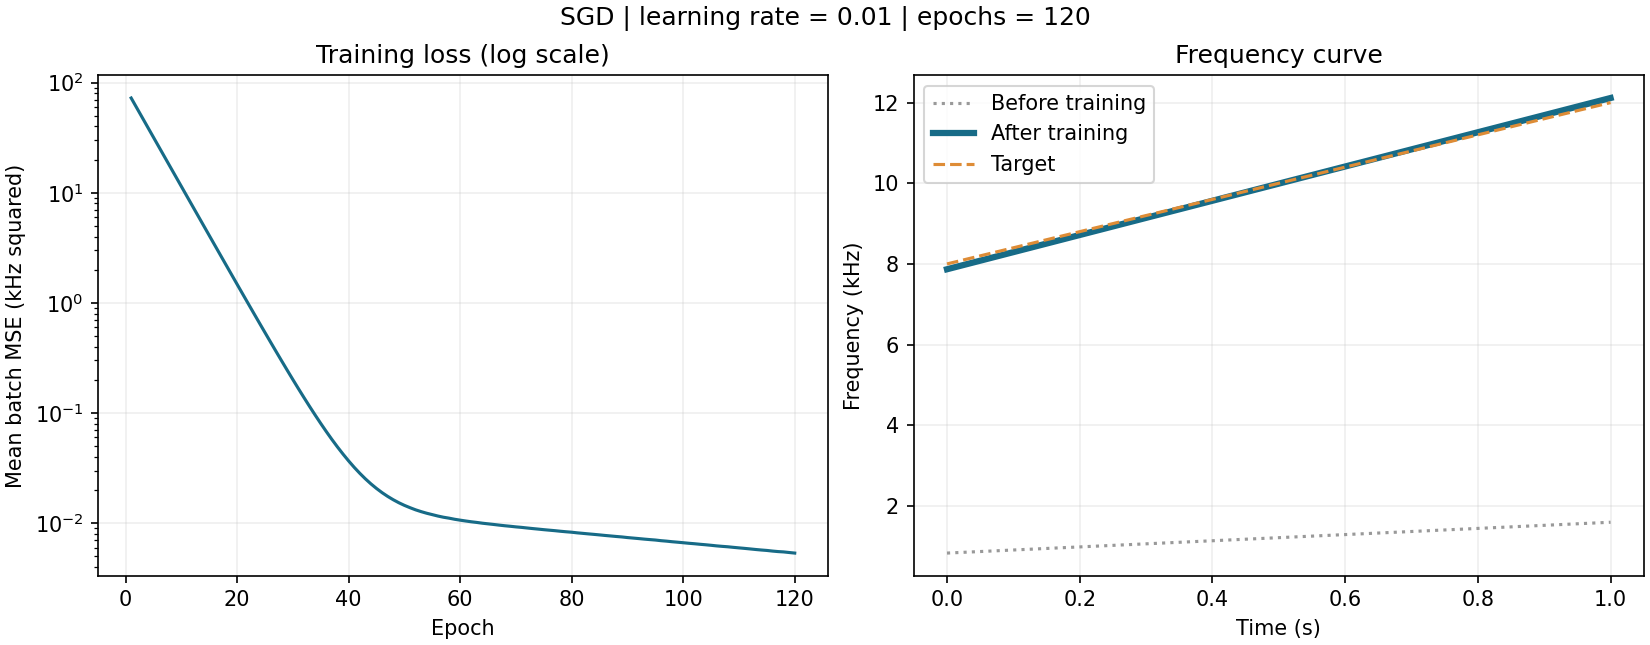

In [14]:
# 我搭好的绘图工具：直接运行即可，不必记忆。
import json
import subprocess
from pathlib import Path
from IPython.display import Image, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
plot_script = project_root / "scripts" / "plot_lesson03.py"
if not plot_script.is_file():
    raise FileNotFoundError("请在 VAE 项目根目录或 notebooks 目录启动此 Notebook。")

output_dir = project_root / "outputs" / "lesson03"
output_dir.mkdir(parents=True, exist_ok=True)
run_name = f"sgd_lr_{learning_rate:g}"
data_path = output_dir / f"{run_name}.json"
figure_path = output_dir / f"{run_name}.png"
plot_data = {
    "learning_rate": learning_rate, "history": history,
    "time": time_s.squeeze(1).tolist(), "target": frequency_khz.squeeze(1).tolist(),
    "initial": initial_prediction.squeeze(1).tolist(), "final": final_prediction.squeeze(1).tolist(),
    "initial_mse": initial_mse, "final_mse": final_mse,
    "weight": model.weight.item(), "bias": model.bias.item(),
}
data_path.write_text(json.dumps(plot_data, ensure_ascii=False, indent=2), encoding="utf-8")
subprocess.run([sys.executable, str(plot_script), str(data_path), str(figure_path)], check=True)
display(Image(filename=str(figure_path)))

## 8．动手：只改学习率，熟悉实验套路

1. 先运行默认 `learning_rate=0.1`，记录下面第一行。
2. 将它改成 `0.01`，保持 `epochs=120`、`batch_size=16` 不变。
3. **从第 3 节的初始化代码格开始，重新往下执行所有代码格**。确认两次初始 w、b 和初始 MSE 一样，再比较训练后结果。
4. 保存 Notebook 的代码、输出和你的观察。无需把参数改回去；写清楚当前保存的是哪次实验即可。

提示：关注“相同训练轮数下学到了多少”。学习率小不等于最终一定更准确；一次实验也不能得出所有任务都应使用同一个学习率。

| 学习率 | 初始 MSE | 训练后 MSE | 学到的 w、b |
|---|---|---|---|
| 0.1 | 78.12411499 | 0.00000003 | w = 4.000630，b = 7.999672 |
| 0.01 | 78.12411499 | 0.00529789 | w = 4.246300，b = 7.867790 |

- 我观察到的曲线和结果差别：损失曲线下降更慢了，而且学到的没那么准了
- 循环中真正更新参数的是哪一句？optimizer.step()。如果只执行 backward，会发生什么：参数不更新，下一轮还是这样，损失不下降，模型停止改善。
- 为什么比较实验前要重新创建模型和优化器：肯定重新初始化w，b，不然第二次直接拿着第一次训练好的结果没法对比不同学习率的训练效果
- 已经熟悉的 PyTorch 操作：模板基本上就是创捷模型，优化器，初始化参数；接着导入训练集，接入模型，正向传播，计算损失，计算梯度，然后梯度下降，反向传播，更新参数；进入下一轮循环。
- 仍有疑问：待填。

下一步：根据你的实际输出与解释确认这套调用顺序，然后进入训练 / 验证 / 测试、模型保存与加载。

## 保存到 Git

先在 PyCharm 保存 Notebook，再在 **VAE 项目根目录的终端**执行。下面只选本课相关文件；其他文档修改可先通过 `git status` 检查后另行处理。

```powershell
git status --short
git add -- "notebooks/03_PyTorch训练循环.ipynb" "scripts/plot_lesson03.py" "README.md" "计划.md" "docs/学习记录.md"
git diff --cached --stat
git commit -m "学习 PyTorch 训练循环并比较学习率"
```

`add` 选择当前已保存版本，`commit` 保存本地历史。需要上传 GitHub 时再执行 `git push`。如果 add 之后又修改了文件，提交前对该文件重新 add。本课不会替你执行这些命令。

参考：[PyTorch 官方训练循环教程](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)。官方网页可能对应更新版本；本课兼容性以 HEUhuqiao 中的实际运行验证为准。